# Análisis Descriptivo de Datos

Empezamos analizando el dataset principal, en tamaño y relevancia para el problema. Open Bandit Dataset.

In [16]:
from pathlib import Path
import pandas as pd

OBD_PATH = Path("Contenido/Datasets/open_bandit_dataset/open_bandit_dataset")
KUAI_PATH = Path("Contenido/Datasets/KuaiRand-Pure/data")


Acorde a los papers base, se tienen las dos políticas aplicadas, con su respectiva etiqueta asociada a la campaña. Veamos esto en la base de datos importada.

In [17]:
policies = sorted(p.name for p in OBD_PATH.iterdir() if p.is_dir())
campaigns = sorted(c.name for c in (OBD_PATH / policies[0]).iterdir() if c.is_dir())
print(policies, campaigns)

['bts', 'random'] ['all', 'men', 'women']


Para el presente análisis se considera la métrica CTR (Click Through Rate) utilizada en el base, que mide la proporción de impresiones que reciben un clic (clics / impresiones).

In [ ]:
COLS = ["item_id", "position", "click"]
DTYPES = {"item_id": "int16", "position": "int8", "click": "int8"}

filas = []
for policy in policies:
    for campaign in campaigns:
        df = pd.read_csv(OBD_PATH / policy / campaign / f"{campaign}.csv",
                         usecols=COLS, dtype=DTYPES)
        filas.append({
            "Política": policy,
            "Campaña": campaign,
            "Registros": len(df),
            "Ítems": df["item_id"].nunique(),
            "Clics": int(df["click"].sum()),
            "CTR": df["click"].mean(),
        })
        del df  # libera memoria 

tabla1 = pd.DataFrame(filas)
tabla1

,Política,Campaña,Registros,Ítems,Clics,CTR
0,bts,all,12357200,80,61208,0.004953
1,bts,men,4077727,34,27495,0.006743
2,bts,women,7765497,46,49539,0.006379
3,random,all,1374327,80,4768,0.003469
4,random,men,452949,34,2321,0.005124
5,random,women,864585,46,4163,0.004815


Observamos que en las tres campañas, la política **bts** obtiene un CTR mayor que **random** y registra más impresiones en comparativa. El CTR es menor al 1% en todos los casos: por ejemplo, en  la campaña men de la política random, hay 2.321 clics en 452.949 impresiones. Caso notablemente menor en comparativa. Luego, como este factor (CTR) varía entre campañas, las políticas se comparan dentro de una misma campaña.

Ahora veamos cómo cada política distribuye las recomendaciones entre los ítems. Para ello consideramos la fracción de exposiciones de cada ítem y el propensity_score, que corresponde a la probabilidad con que la política eligió el ítem mostrado (columna incluida en el dataset).

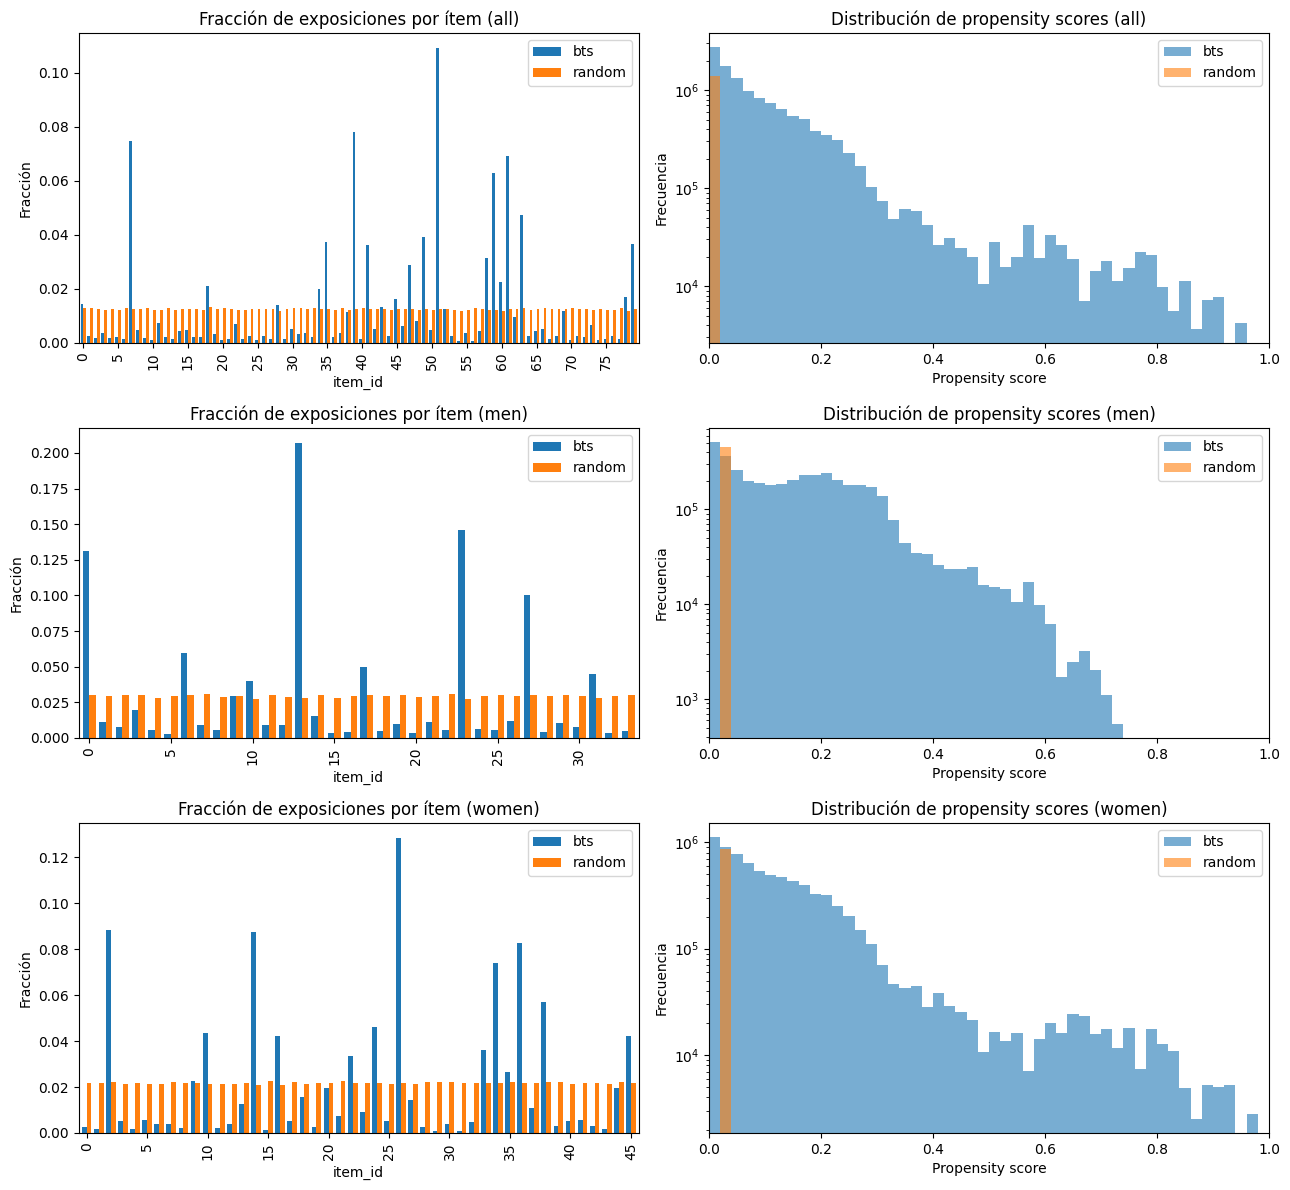

In [ ]:

import numpy as np
import matplotlib.pyplot as plt


cols = ["item_id", "propensity_score"]
dtypes = {"item_id": "int16", "propensity_score": "float32"}

fig, axes = plt.subplots(len(campaigns), 2, figsize=(13, 4 * len(campaigns)))

for i, campaign in enumerate(campaigns):
    data = {p: pd.read_csv(OBD_PATH / p / campaign / f"{campaign}.csv", usecols=cols, dtype=dtypes)
            for p in policies}

    exposicion = pd.DataFrame({p: df["item_id"].value_counts(normalize=True) for p, df in data.items()}).sort_index()
    exposicion.plot.bar(ax=axes[i, 0], width=0.8)
    axes[i, 0].set(title=f"Fracción de exposiciones por ítem ({campaign})", xlabel="item_id", ylabel="Fracción")
    axes[i, 0].set_xticks(axes[i, 0].get_xticks()[::5])  # ajuste de escala

    bins = np.linspace(0, 1, 51) 
    for p, df in data.items():
        axes[i, 1].hist(df["propensity_score"], bins=bins, alpha=0.6, label=p)
    axes[i, 1].set_xlim(0, 1)
    axes[i, 1].set(title=f"Distribución de propensity scores ({campaign})", xlabel="Propensity score",
                   ylabel="Frecuencia", yscale="log")
    axes[i, 1].legend()

    del data  

plt.tight_layout()
#plt.savefig("fig_obd_campanas.png", dpi=200, bbox_inches="tight")
plt.show()

En las tres campañas, random distribuye sus exposiciones de forma casi uniforme entre los ítems y todos sus propensity scores toman un único valor por esta razón. 

Mientras que bts concentra las exposiciones en pocos ítems (en **men**, un solo ítem recibe cerca del 20% de las impresiones) y sus propensity scores se distribuyen entre  0 y 0,95 en `all` y `women`, mientras que en `men` aproximadamente entre 0 y 0,73.

Codigo Individual por campaña (utilizado para informe)

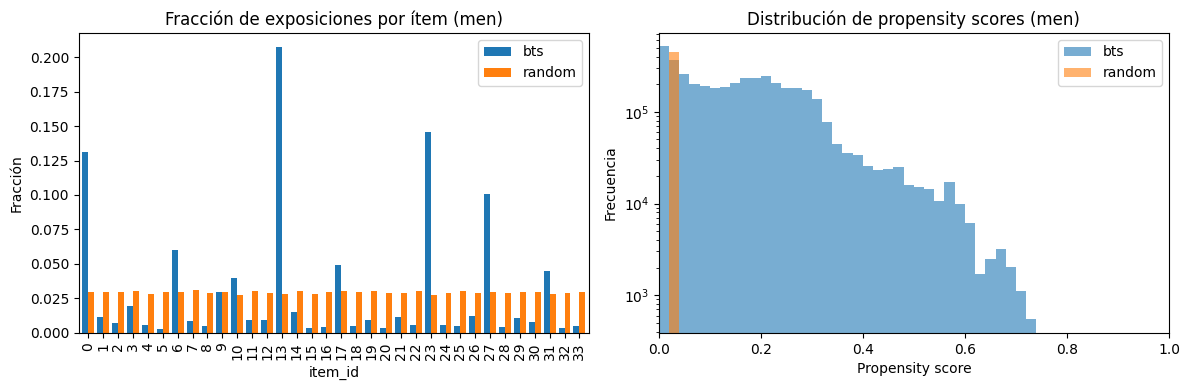

In [ ]:


CAMPAIGN = "men"  # se cambia según campaña

cols = ["item_id", "propensity_score"]
dtypes = {"item_id": "int16", "propensity_score": "float32"}
data = {p: pd.read_csv(OBD_PATH / p / CAMPAIGN / f"{CAMPAIGN}.csv", usecols=cols, dtype=dtypes)
        for p in policies}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))


exposicion = pd.DataFrame({p: df["item_id"].value_counts(normalize=True) for p, df in data.items()}).sort_index()
exposicion.plot.bar(ax=axes[0], width=0.8)
axes[0].set(title=f"Fracción de exposiciones por ítem ({CAMPAIGN})", xlabel="item_id", ylabel="Fracción")


bins = np.linspace(0, 1, 51) 
for p, df in data.items():
    axes[1].hist(df["propensity_score"], bins=bins, alpha=0.6, label=p)
axes[1].set_xlim(0, 1)
axes[1].set(title=f"Distribución de propensity scores ({CAMPAIGN})", xlabel="Propensity score",
            ylabel="Frecuencia", yscale="log")
axes[1].legend()

plt.tight_layout()
#plt.savefig(f"fig_obd_{CAMPAIGN}.png", dpi=200, bbox_inches="tight")
plt.show()

Estadísticos de las impresiones por ítem y del propensity score por campaña.

In [24]:
CAMPAIGN = "men"

In [21]:
pct = [.25, .5, .75, .9]
resumen = {}
for p in policies:
    df = pd.read_csv(OBD_PATH / p / CAMPAIGN / f"{CAMPAIGN}.csv", usecols=cols, dtype=dtypes)
    resumen[(p, "Impresiones por ítem")] = df["item_id"].value_counts().describe(percentiles=pct)
    resumen[(p, "Propensity score")] = df["propensity_score"].describe(percentiles=pct)
    del df

tabla_obd = pd.DataFrame(resumen).round(4)
tabla_obd

bts                                random  \
      Impresiones por ítem Propensity score Impresiones por ítem   
count              34.0000     4.077727e+06              34.0000   
mean           119933.1471     1.641000e-01           13322.0294   
std            193794.1160     1.278000e-01             383.6230   
min             11852.0000     0.000000e+00           12514.0000   
25%             21565.2500     4.980000e-02           13162.7500   
50%             37621.5000     1.539000e-01           13301.5000   
75%            109825.0000     2.451000e-01           13574.0000   
90%            360131.4000     3.165000e-01           13737.9000   
max            845146.0000     7.253000e-01           14014.0000   

                        
      Propensity score  
count      452949.0000  
mean            0.0294  
std             0.0000  
min             0.0294  
25%             0.0294  
50%             0.0294  
75%             0.0294  
90%             0.0294  
max             0.0294

### Considerando campaña Men

En **random**, cada ítem recibe entre 12.514 y 14.014 impresiones (desviación estándar 384) y el propensity score es constante, igual a 0,0294 = 1/34. 

Por otro lado, en **bts**, las impresiones por ítem van de 11.852 a 845.146 (desviación estándar 193.794), y el propensity score tiene mediana 0,154 y valores mínimos cercanos a 0.

In [25]:
CAMPAIGN = "women"

In [26]:
pct = [.25, .5, .75, .9]
resumen = {}
for p in policies:
    df = pd.read_csv(OBD_PATH / p / CAMPAIGN / f"{CAMPAIGN}.csv", usecols=cols, dtype=dtypes)
    resumen[(p, "Impresiones por ítem")] = df["item_id"].value_counts().describe(percentiles=pct)
    resumen[(p, "Propensity score")] = df["propensity_score"].describe(percentiles=pct)
    del df

tabla_obd = pd.DataFrame(resumen).round(4)
tabla_obd

bts                                random  \
      Impresiones por ítem Propensity score Impresiones por ítem   
count              46.0000     7.765497e+06              46.0000   
mean           168815.1522     1.362000e-01           18795.3261   
std            228857.5566     1.453000e-01             336.5840   
min              6140.0000     0.000000e+00           18087.0000   
25%             22341.7500     3.840000e-02           18568.2500   
50%             44395.0000     9.660000e-02           18794.5000   
75%            245961.7500     1.833000e-01           19001.7500   
90%            509103.0000     2.774000e-01           19214.5000   
max            998777.0000     9.628000e-01           19511.0000   

                        
      Propensity score  
count      864585.0000  
mean            0.0217  
std             0.0000  
min             0.0217  
25%             0.0217  
50%             0.0217  
75%             0.0217  
90%             0.0217  
max             0.0217

### Considerando campaña Women

En **random**, cada ítem recibe entre 18.087 y 19.511 impresiones (desviación estándar 336) y el propensity score es constante, igual a 0,0217.

Por otro lado, en **bts**, las impresiones por ítem van de 6.140 a 998.777 (desviación estándar 228.857), el propensity score tiene mediana 0,0966 y valores mínimos cercanos a 0.

In [27]:
CAMPAIGN = "all"

In [28]:
pct = [.25, .5, .75, .9]
resumen = {}
for p in policies:
    df = pd.read_csv(OBD_PATH / p / CAMPAIGN / f"{CAMPAIGN}.csv", usecols=cols, dtype=dtypes)
    resumen[(p, "Impresiones por ítem")] = df["item_id"].value_counts().describe(percentiles=pct)
    resumen[(p, "Propensity score")] = df["propensity_score"].describe(percentiles=pct)
    del df

tabla_obd = pd.DataFrame(resumen).round(4)
tabla_obd

bts                                random  \
      Impresiones por ítem Propensity score Impresiones por ítem   
count         8.000000e+01     1.235720e+07              80.0000   
mean          1.544650e+05     1.094000e-01           17179.0875   
std           2.532064e+05     1.327000e-01             404.4349   
min           8.546000e+03     0.000000e+00           16325.0000   
25%           2.469700e+04     2.350000e-02           16924.2500   
50%           4.496500e+04     6.660000e-02           17200.0000   
75%           1.577325e+05     1.489000e-01           17485.2500   
90%           4.521057e+05     2.411000e-01           17651.6000   
max           1.351176e+06     9.542000e-01           18184.0000   

                        
      Propensity score  
count     1.374327e+06  
mean      1.250000e-02  
std       0.000000e+00  
min       1.250000e-02  
25%       1.250000e-02  
50%       1.250000e-02  
75%       1.250000e-02  
90%       1.250000e-02  
max       1.250000e-02

### Considerando Campaña "all"

En **random**, cada ítem recibe entre 16.325 y 18.184 impresiones (desviación estándar 404,43) y el propensity score es constante, igual a 0,0125.

Por otro lado, en **bts**, las impresiones por ítem van de 8.546 a 1.351.176 (desviación estándar 253.206), el propensity score tiene mediana 0,0666 y valores mínimos cercanos a 0.



Ahora veamos el dataset KuaiRand-Pure. Se listan los logs disponibles en la carpeta; las fechas y si la exposición es aleatoria se obtienen de las columnas date e is_rand.

In [22]:
filas = []
for archivo in sorted(KUAI_PATH.glob("log_*.csv")):
    df = pd.read_csv(archivo, usecols=["user_id", "video_id", "date", "is_click", "is_rand"])
    filas.append({
        "Archivo": archivo.name,
        "Desde": df["date"].min(),
        "Hasta": df["date"].max(),
        "Fracción aleatoria (is_rand)": df["is_rand"].mean(),
        "Interacciones": len(df),
        "Usuarios": df["user_id"].nunique(),
        "Videos": df["video_id"].nunique(),
        "CTR": df["is_click"].mean(),
    })
    del df

tabla2 = pd.DataFrame(filas)
tabla2

,Archivo,Desde,Hasta,Fracción aleatoria (is_rand),Interacciones,Usuarios,Videos,CTR
0,log_random_4_22_to_5_08_pure.csv,20220422,20220508,1.0,1186059,27285,7583,0.176158
1,log_standard_4_08_to_4_21_pure.csv,20220409,20220421,0.0,1141112,26210,7538,0.463447
2,log_standard_4_22_to_5_08_pure.csv,20220422,20220508,0.0,295497,25877,6618,0.445003


KuaiRand-Pure contiene tres logs. 

Uno tiene is_rand = 1 en todas sus filas, es decir, exposición aleatoria: 1.186.059 interacciones entre el 22/04 y el 08/05/2022. 

Los otros dos tienen is_rand = 0. El CTR del log aleatorio (0,18) es menor en comparativa con los logs estándar (0,46 y 0,45). 



Ahora veamos las interacciones por usuario y por video, considerando todos los logs.

In [23]:
logs = pd.concat([pd.read_csv(f, usecols=["user_id", "video_id"]) for f in sorted(KUAI_PATH.glob("log_*.csv"))])

pct = [.25, .5, .75, .9]
conteos = pd.DataFrame({
    "Interacciones por usuario": logs["user_id"].value_counts().describe(percentiles=pct),
    "Interacciones por video": logs["video_id"].value_counts().describe(percentiles=pct),
}).round(1)
del logs
conteos

,Interacciones por usuario,Interacciones por video
count,27285.0,7583.0
mean,96.1,345.9
std,85.7,434.7
min,10.0,3.0
25%,42.0,183.0
50%,73.0,218.0
75%,121.0,337.0
90%,190.0,627.0
max,1766.0,10515.0


La media de interacciones por usuario (96,1) supera a la mediana (73), y la de interacciones por video (345,9) supera a la mediana (218). Ambas distribuciones tienen colas largas: el máximo es 1.766 interacciones para un usuario y 10.515 para un video. Cada usuario tiene al menos 10 interacciones.

Por último, veamos las estadísticas generales de KuaiRand-Pure, considerando todos los logs. La densidad se calcula con los pares usuario–video distintos sobre el total de pares posibles (usuarios × videos).

In [29]:
logs = pd.concat([pd.read_csv(f, usecols=["user_id", "video_id"]) for f in sorted(KUAI_PATH.glob("log_*.csv"))])

n_usuarios = logs["user_id"].nunique()
n_videos = logs["video_id"].nunique()
n_pares = len(logs.drop_duplicates())

general = pd.Series({
    "N° de usuarios": n_usuarios,
    "N° de videos": n_videos,
    "N° de interacciones": len(logs),
    "Pares usuario–video distintos": n_pares,
    "Densidad (%)": 100 * n_pares / (n_usuarios * n_videos),
    "Interacciones promedio por usuario": len(logs) / n_usuarios,
    "Interacciones promedio por video": len(logs) / n_videos,
}).round(2)
del logs
general

N° de usuarios                          27285.00
N° de videos                             7583.00
N° de interacciones                   2622668.00
Pares usuario–video distintos         2560247.00
Densidad (%)                                1.24
Interacciones promedio por usuario         96.12
Interacciones promedio por video          345.86
dtype: float64